# 01 — Data Understanding

## Project: Customer Retention & Revenue Intelligence

In this notebook, we will explore the Online Retail II dataset using basic Python and Pandas. The goal is to understand what the data contains before cleaning it or building a machine-learning model.

**Learning rule:** Run one code cell at a time. Read the explanation, inspect the output, and write down what you notice. We will not use complicated functions or production code here.

### Dataset
The dataset contains retail transactions. Each row generally represents an item on an invoice. It includes invoice details, products, quantities, prices, customers and countries.

Expected file: `data/raw/online_retail_II.xlsx` (download it from the UCI Online Retail II dataset page and place it in this folder structure).


## 1. Import the libraries

Pandas helps us load and analyse tabular data. Matplotlib helps us create simple charts. `Path` helps us work with file paths.

In [30]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path


## 2. Find and load the Excel workbook

This notebook expects Jupyter to be opened from the `customer-retention-revenue-intelligence` project folder. The workbook contains multiple sheets, so we load the sheets and combine them into one DataFrame.

In [31]:
data_path = Path("01-machine-learning/customer-retention-revenue-intelligence/data/raw/online_retail_II.xlsx")

print("Workbook exists:", data_path.exists())
print("Workbook path:", data_path.resolve())


Workbook exists: False
Workbook path: /Users/nithiii/Downloads/data-science-ai-portfolio/01-machine-learning/customer-retention-revenue-intelligence/notebooks/01-machine-learning/customer-retention-revenue-intelligence/data/raw/online_retail_II.xlsx


In [32]:
from pathlib import Path

data_folder = Path("../data/raw")

print("Data folder exists:", data_folder.exists())

if data_folder.exists():
    print("Files:", list(data_folder.iterdir()))

Data folder exists: True
Files: [PosixPath('../data/raw/.gitkeep'), PosixPath('../data/raw/online_retail_II.xlsx')]


In [33]:
data_path = Path("../data/raw/online_retail_II.xlsx")

print("File exists:", data_path.exists())
print("Full path:", data_path.resolve())

File exists: True
Full path: /Users/nithiii/Downloads/data-science-ai-portfolio/01-machine-learning/customer-retention-revenue-intelligence/data/raw/online_retail_II.xlsx


If `Workbook exists` is `False`, stop here. Download the dataset and save it at the path shown above. Do not continue until the file is available.

In [34]:
# Read every worksheet into a dictionary of DataFrames
sheets = pd.read_excel(data_path, sheet_name=None)

print("Worksheet names:", list(sheets.keys()))

# Combine the worksheets into one DataFrame
df = pd.concat(sheets.values(), ignore_index=True)

print("Dataset loaded successfully!")


Worksheet names: ['Year 2009-2010', 'Year 2010-2011']
Dataset loaded successfully!


## 3. First look at the data

`head()` shows the first five rows. `shape` tells us the number of rows and columns. `columns` lists the column names.

In [35]:
df.head()


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom


In [36]:
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])
print("Column names:")
print(df.columns.tolist())


Number of rows: 1067371
Number of columns: 8
Column names:
['Invoice', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'Price', 'Customer ID', 'Country']


## 4. Understand column data types

`info()` shows each column's data type and how many non-missing values it contains. `describe()` gives summary statistics for numeric columns.

In [37]:
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1067371 entries, 0 to 1067370
Data columns (total 8 columns):
 #   Column       Non-Null Count    Dtype         
---  ------       --------------    -----         
 0   Invoice      1067371 non-null  object        
 1   StockCode    1067371 non-null  object        
 2   Description  1062989 non-null  object        
 3   Quantity     1067371 non-null  int64         
 4   InvoiceDate  1067371 non-null  datetime64[ns]
 5   Price        1067371 non-null  float64       
 6   Customer ID  824364 non-null   float64       
 7   Country      1067371 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 65.1+ MB


In [38]:
df.describe()


,Quantity,InvoiceDate,Price,Customer ID
count,1.067371e+06,1067371,1.067371e+06,824364.000000
mean,9.938898e+00,2011-01-02 21:13:55.394028544,4.649388e+00,15324.638504
min,-8.099500e+04,2009-12-01 07:45:00,-5.359436e+04,12346.000000
25%,1.000000e+00,2010-07-09 09:46:00,1.250000e+00,13975.000000
50%,3.000000e+00,2010-12-07 15:28:00,2.100000e+00,15255.000000
75%,1.000000e+01,2011-07-22 10:23:00,4.150000e+00,16797.000000
max,8.099500e+04,2011-12-09 12:50:00,3.897000e+04,18287.000000
std,1.727058e+02,NaN,1.235531e+02,1697.464450


## 5. Check missing values and duplicate rows

A missing value means a field has no recorded value. A duplicate row is a row repeated exactly. At this stage, we are only measuring them—we are not deleting anything.

In [39]:
missing_values = df.isnull().sum().sort_values(ascending=False)
display(missing_values)

print("Exact duplicate rows:", df.duplicated().sum())


Customer ID    243007
Description      4382
Invoice             0
StockCode           0
Quantity            0
InvoiceDate         0
Price               0
Country             0
dtype: int64

Exact duplicate rows: 34335


## 6. Understand the date range

The invoice date tells us when each transaction happened. Convert it to a datetime value so Pandas can work with dates.

In [40]:
df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"], errors="coerce")

print("Earliest invoice date:", df["InvoiceDate"].min())
print("Latest invoice date:", df["InvoiceDate"].max())


Earliest invoice date: 2009-12-01 07:45:00
Latest invoice date: 2011-12-09 12:50:00


## 7. Explore quantities and prices

Look at the minimum, maximum, average and quartiles. Negative quantities can occur in returned or cancelled transactions, so do not remove them yet.

In [41]:
display(df[["Quantity", "Price"]].describe())


,Quantity,Price
count,1.067371e+06,1.067371e+06
mean,9.938898e+00,4.649388e+00
std,1.727058e+02,1.235531e+02
min,-8.099500e+04,-5.359436e+04
25%,1.000000e+00,1.250000e+00
50%,3.000000e+00,2.100000e+00
75%,1.000000e+01,4.150000e+00
max,8.099500e+04,3.897000e+04


## 8. Explore sales by country

First calculate line revenue as `Quantity × Price`. This is a simple exploratory measure; we will define the final valid-sales rules during data cleaning.

In [42]:
df["LineRevenue"] = df["Quantity"] * df["Price"]

revenue_by_country = (
    df.groupby("Country")["LineRevenue"]
      .sum()
      .sort_values(ascending=False)
      .head(10)
)

display(revenue_by_country)


Country
United Kingdom    1.638258e+07
EIRE              6.155196e+05
Netherlands       5.485249e+05
Germany           4.179886e+05
France            3.281918e+05
Australia         1.671291e+05
Switzerland       9.972876e+04
Spain             9.185948e+04
Sweden            8.780942e+04
Denmark           6.574109e+04
Name: LineRevenue, dtype: float64

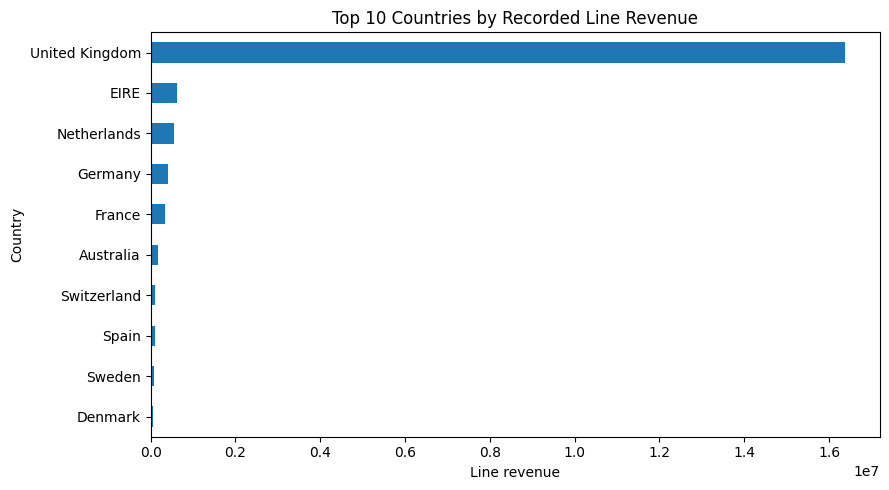

In [43]:
revenue_by_country.sort_values().plot(kind="barh", figsize=(9, 5))
plt.title("Top 10 Countries by Recorded Line Revenue")
plt.xlabel("Line revenue")
plt.ylabel("Country")
plt.tight_layout()
plt.show()


## 9. Explore monthly transaction activity

Count the number of invoice rows per month. This is a first look at transaction activity, not yet a cleaned monthly sales metric.

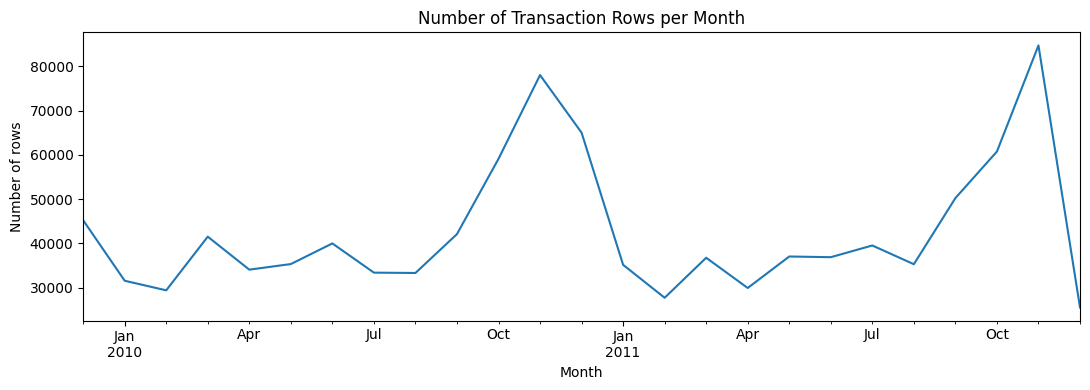

In [44]:
monthly_rows = df.set_index("InvoiceDate").resample("MS").size()

monthly_rows.plot(figsize=(11, 4))
plt.title("Number of Transaction Rows per Month")
plt.xlabel("Month")
plt.ylabel("Number of rows")
plt.tight_layout()
plt.show()


## 10. Your observations

Answer these in your own words. It is fine if you are unsure—we will discuss your answers together.

1. How many rows and columns are in the dataset?
2. Which columns contain the most missing values? Why might Customer ID be missing for some transactions?
3. What date range does the dataset cover?
4. Did you notice negative quantities or prices? What might they represent?
5. Which country has the highest recorded line revenue in this initial exploration?
6. What patterns do you notice in monthly transaction activity?

### Important
These are initial observations from raw data. We have not yet removed cancellations, handled missing customer IDs, removed duplicates, or defined valid purchases. We will make and explain those decisions in the next stage.



## 1. SHAP Model Explainability

SHAP (SHapley Additive exPlanations) helps explain how individual features contribute to the predictions made by our trained Random Forest model.

Our objective is to understand which historical customer behaviours influence the prediction of a repeat purchase within the next 90 days.

### Target definition

- **Class 1:** Customer makes at least one valid purchase within the next 90 days.
- **Class 0:** Customer makes no valid purchase within the next 90 days.

The SHAP analysis focuses on the positive class (Class 1).


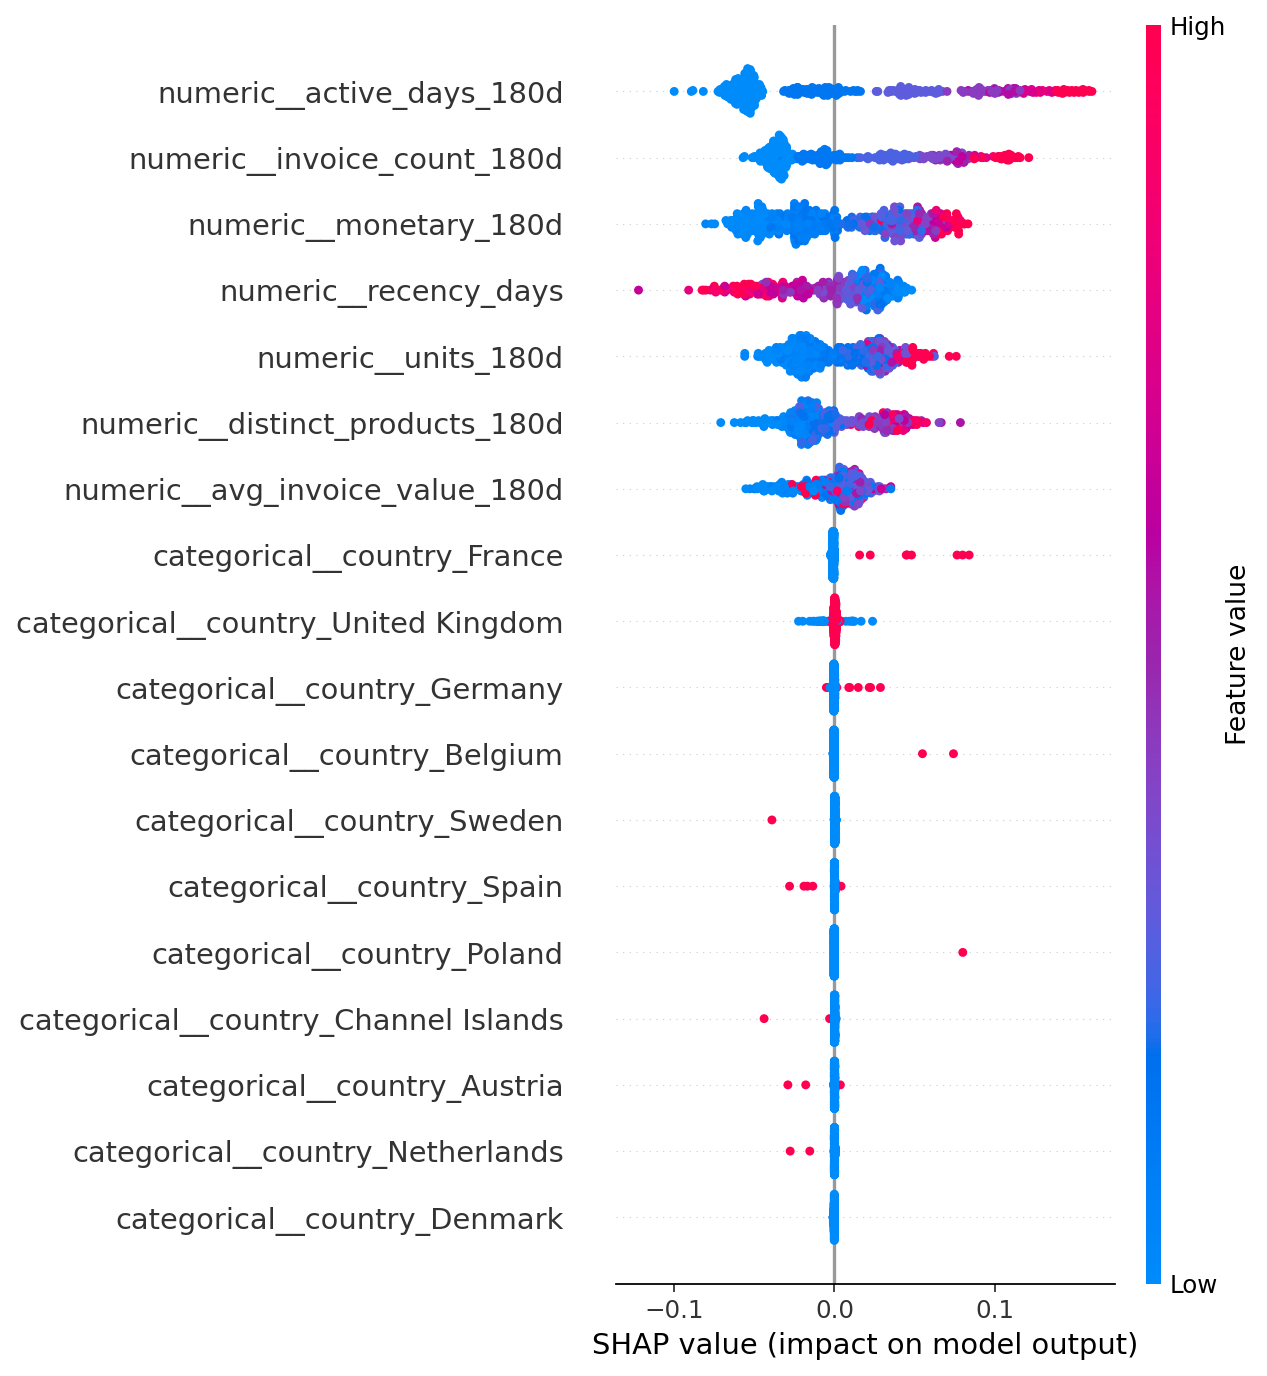

In [45]:

from pathlib import Path
from IPython.display import display, Image
import pandas as pd

REPORTS = Path("../reports")

shap_plot = REPORTS / "shap_summary.png"

if shap_plot.exists():
    display(Image(filename=str(shap_plot)))
else:
    print("SHAP summary plot not found. Run python -m src.explain first.")



## 2. Global Feature Importance

Mean absolute SHAP values measure the average magnitude of each feature's contribution to the model predictions.

A larger value indicates greater influence on the model's predictions. However, this measure does not indicate whether a feature increases or decreases the probability of repeat purchase.


In [46]:

importance_file = REPORTS / "shap_feature_importance.csv"

if importance_file.exists():
    shap_importance = pd.read_csv(importance_file)

    shap_importance.index = range(1, len(shap_importance) + 1)
    shap_importance.index.name = "Rank"

    display(shap_importance.head(20).round(6))
else:
    print("SHAP importance CSV not found. Run python -m src.explain first.")


,feature,mean_abs_shap
Rank,,
1,numeric__active_days_180d,0.060494
2,numeric__invoice_count_180d,0.041881
3,numeric__monetary_180d,0.038203
4,numeric__recency_days,0.027235
5,numeric__units_180d,0.024485
6,numeric__distinct_products_180d,0.022749
7,numeric__avg_invoice_value_180d,0.013670
8,categorical__country_France,0.001462
9,categorical__country_United Kingdom,0.001281



## 3. Business Interpretation

The SHAP analysis identifies historical customer purchasing behaviour as the strongest source of predictive information.

### Key findings

1. **Active days (180d):** The strongest feature, indicating the importance of customer engagement frequency.
2. **Invoice count (180d):** Purchase frequency provides an important signal for future purchasing behaviour.
3. **Monetary value (180d):** Historical spending contributes substantially to model predictions.
4. **Recency days:** The time elapsed since the customer's last purchase influences repeat-purchase predictions.
5. **Units and distinct products:** Purchase volume and product diversity provide additional predictive information.

Country-level features have considerably smaller global SHAP importance than the numerical behavioural features.

### Business implications

- Identify customers with declining purchase activity.
- Monitor changes in purchase frequency and recency.
- Use historical spending and engagement to support customer segmentation.
- Prioritise customer retention campaigns using model predictions.

### Important limitations

SHAP measures model associations, not causal relationships. Mean absolute SHAP values do not indicate the direction of a feature's effect.

Further analysis using SHAP summary plots and individual explanations is required to understand whether higher or lower feature values push predictions towards repeat purchase.
